# 1. Loading the Dataset
## 1.1 Load Wine Classification Dataset
## 1.2 Create the DataFrame

In [82]:

import pandas as pd
import numpy as np
from sklearn.datasets import load_wine

# 1.1 Load Wine Classification Dataset
wine = load_wine()

# 1.2 Create feature DataFrame and target Series
X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = pd.Series(wine.target, name="target")

# First five rows
print("FIRST FIVE ROWS")
display(X.head())

# Dataset shape
print("\nDATASET SHAPE")
print("Samples:", X.shape[0])
print("Features:", X.shape[1])

# Feature names
print("\nFEATURE NAMES")
print(X.columns.tolist())

# Target labels and names
print("\nTARGET LABELS")
print(np.unique(y))

print("\nTARGET NAMES")
print(wine.target_names)

# Class-label mapping
print("\nCLASS-LABEL MAPPING")
for label, name in enumerate(wine.target_names):
    print(f"{label}: {name}")

# Class distribution
print("\nCLASS DISTRIBUTION")
print(y.value_counts().sort_index())


FIRST FIVE ROWS


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0



DATASET SHAPE
Samples: 178
Features: 13

FEATURE NAMES
['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']

TARGET LABELS
[0 1 2]

TARGET NAMES
['class_0' 'class_1' 'class_2']

CLASS-LABEL MAPPING
0: class_0
1: class_1
2: class_2

CLASS DISTRIBUTION
target
0    59
1    71
2    48
Name: count, dtype: int64


**Interpretation – Dataset Overview**

The Wine dataset contains 178 samples and 13 numerical features. There are three classes: 0, 1, and 2.

Class 0 has 59 samples, Class 1 has 71 samples, and Class 2 has 48 samples. Class 1 has the most samples.

# 2. Dataset Quality Checks
## 2.1 Missing Values and Duplicates
## 2.2 Potential Outliers
## 2.3 Data Types

In [83]:

# 2.1 Missing Values and Duplicates

print("MISSING VALUES BY FEATURE")
print(X.isnull().sum().to_string())

print("\nTOTAL MISSING VALUES")
print(X.isnull().sum().sum())

print("\nDUPLICATE ROWS")
print(X.duplicated().sum())


# 2.2 Potential Outliers - IQR Method

print("\nPOTENTIAL OUTLIERS (IQR METHOD)")

Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = X.lt(lower_bound) | X.gt(upper_bound)
outlier_counts = outliers.sum()

print(outlier_counts.to_string())

print("\nRows with at least one potential outlier:")
print(outliers.any(axis=1).sum())


# 2.3 Data Types

print("\nFEATURE DATA TYPES")
print(X.dtypes.to_string())

print("\nNUMBER OF NUMERICAL FEATURES")
print(X.select_dtypes(include="number").shape[1])

print("\nNUMBER OF CATEGORICAL FEATURES")
print(X.select_dtypes(exclude="number").shape[1])


MISSING VALUES BY FEATURE
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0

TOTAL MISSING VALUES
0

DUPLICATE ROWS
0

POTENTIAL OUTLIERS (IQR METHOD)
alcohol                         0
malic_acid                      3
ash                             3
alcalinity_of_ash               4
magnesium                       4
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 2
color_intensity                 4
hue                             1
od280/od315_of_diluted_wines    0
proline                         0

Rows with at l

**Interpretation – Dataset Quality Checks**

The Wine dataset has 13 numerical features and no categorical features. There are no missing values or duplicate rows.

We used the IQR method to find possible outliers. We kept these values because they are not always data errors.

# 3. Exploratory Data Analysis
## 3.1 Descriptive Statistics

In [84]:

# 3.1 Descriptive Statistics - Wine Dataset

statistics = pd.DataFrame({
    "Mean": X.mean(),
    "Median": X.median(),
    "Minimum": X.min(),
    "Maximum": X.max(),
    "Standard Deviation": X.std(),
    "Q1": X.quantile(0.25),
    "Q3": X.quantile(0.75)
})

print("DESCRIPTIVE STATISTICS - WINE DATASET")
display(statistics.round(4))

print("\nNUMBER OF FEATURES:", len(statistics))


DESCRIPTIVE STATISTICS - WINE DATASET


,Mean,Median,Minimum,Maximum,Standard Deviation,Q1,Q3
alcohol,13.0006,13.050,11.03,14.83,0.8118,12.3625,13.6775
malic_acid,2.3363,1.865,0.74,5.80,1.1171,1.6025,3.0825
ash,2.3665,2.360,1.36,3.23,0.2743,2.2100,2.5575
alcalinity_of_ash,19.4949,19.500,10.60,30.00,3.3396,17.2000,21.5000
magnesium,99.7416,98.000,70.00,162.00,14.2825,88.0000,107.0000
total_phenols,2.2951,2.355,0.98,3.88,0.6259,1.7425,2.8000
flavanoids,2.0293,2.135,0.34,5.08,0.9989,1.2050,2.8750
nonflavanoid_phenols,0.3619,0.340,0.13,0.66,0.1245,0.2700,0.4375
proanthocyanins,1.5909,1.555,0.41,3.58,0.5724,1.2500,1.9500
color_intensity,5.0581,4.690,1.28,13.00,2.3183,3.2200,6.2000



NUMBER OF FEATURES: 13


## 3.2 Class Distribution and Correlations

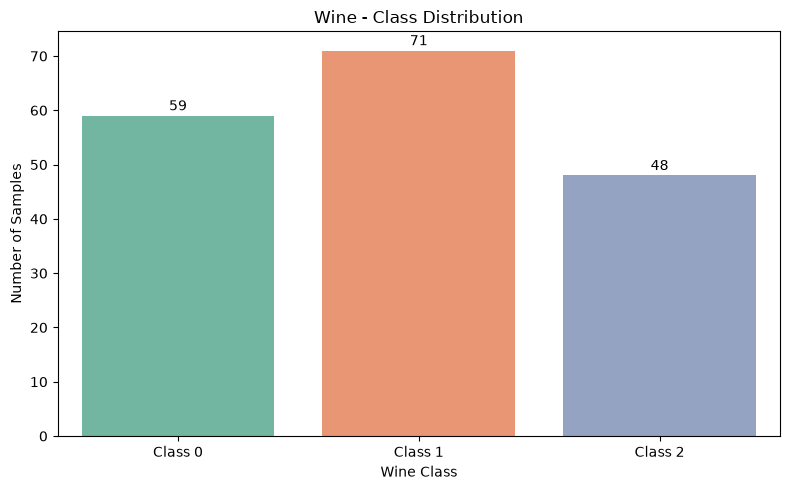

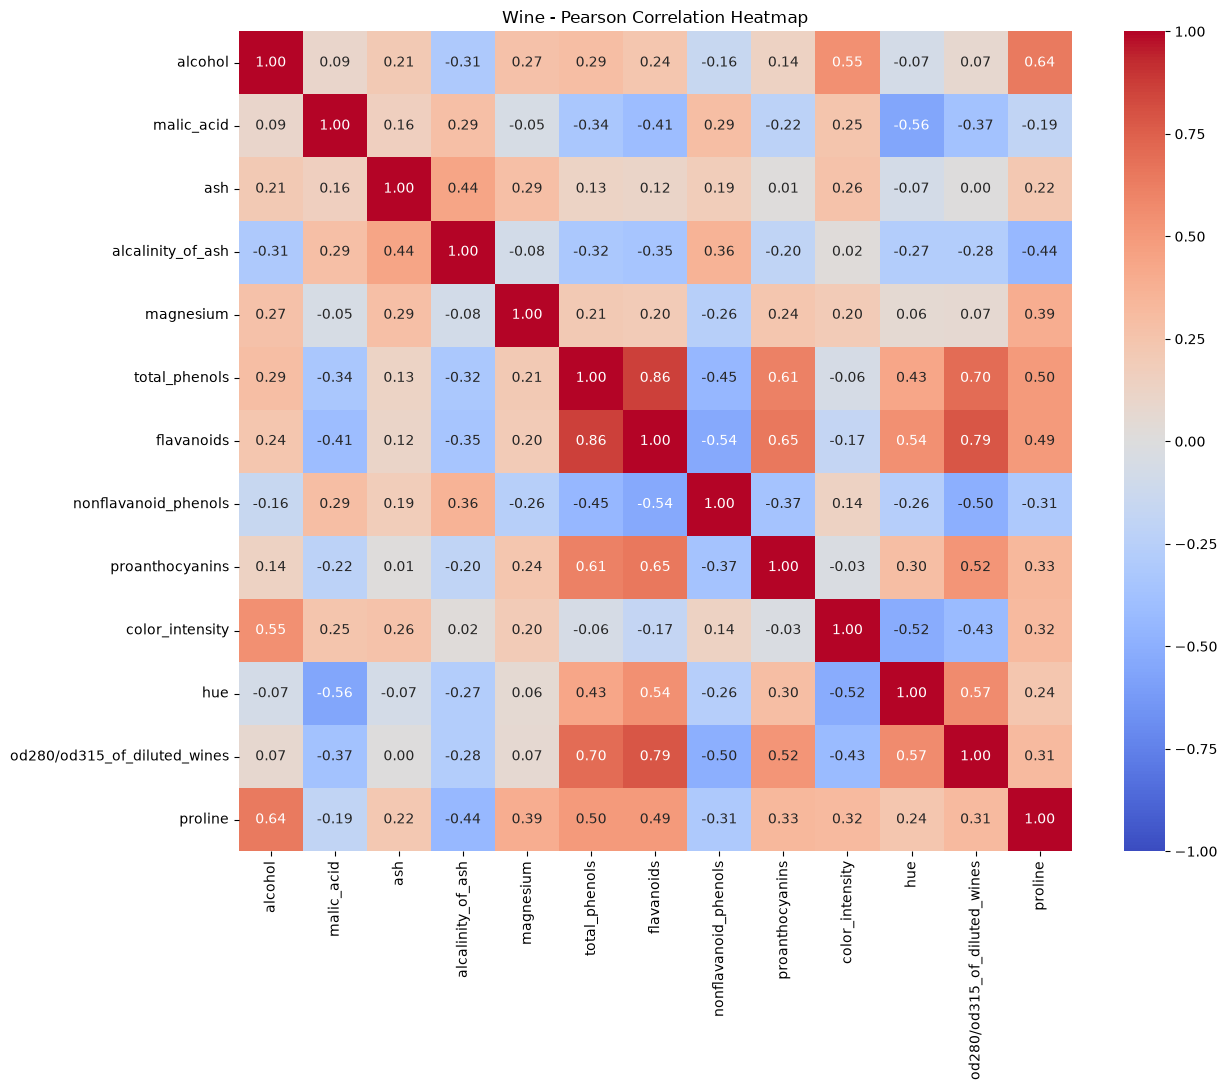

TOP 3 STRONGEST FEATURE CORRELATIONS
total_phenols <-> flavanoids: Correlation = 0.8646
flavanoids <-> od280/od315_of_diluted_wines: Correlation = 0.7872
total_phenols <-> od280/od315_of_diluted_wines: Correlation = 0.6999


In [85]:

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os

os.makedirs("figures", exist_ok=True)

# 1. Wine Class Distribution
class_counts = y.value_counts().sort_index()

plt.figure(figsize=(8, 5))

class_labels = ["Class 0", "Class 1", "Class 2"]

sns.barplot(
    x=class_labels,
    y=class_counts.values,
    hue=class_labels,
    palette="Set2",
    legend=False
)

for i, count in enumerate(class_counts.values):
    plt.text(i, count + 1, str(count), ha="center")

plt.title("Wine - Class Distribution")
plt.xlabel("Wine Class")
plt.ylabel("Number of Samples")

plt.tight_layout()
plt.savefig(
    "figures/wine_class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# 2. Pearson Correlation Heatmap
correlation_matrix = X.corr(method="pearson")

plt.figure(figsize=(13, 11))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Wine - Pearson Correlation Heatmap")
plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()
plt.savefig(
    "figures/wine_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# 3. Three Strongest Unique Correlations
absolute_corr = correlation_matrix.abs()

upper_triangle = absolute_corr.where(
    np.triu(
        np.ones(absolute_corr.shape),
        k=1
    ).astype(bool)
)

top_3_correlations = (
    upper_triangle.stack()
    .sort_values(ascending=False)
    .head(3)
)

print("TOP 3 STRONGEST FEATURE CORRELATIONS")

for (feature1, feature2), value in top_3_correlations.items():

    original_value = correlation_matrix.loc[
        feature1, feature2
    ]

    print(
        f"{feature1} <-> {feature2}: "
        f"Correlation = {original_value:.4f}"
    )


## 3.3 Boxplots

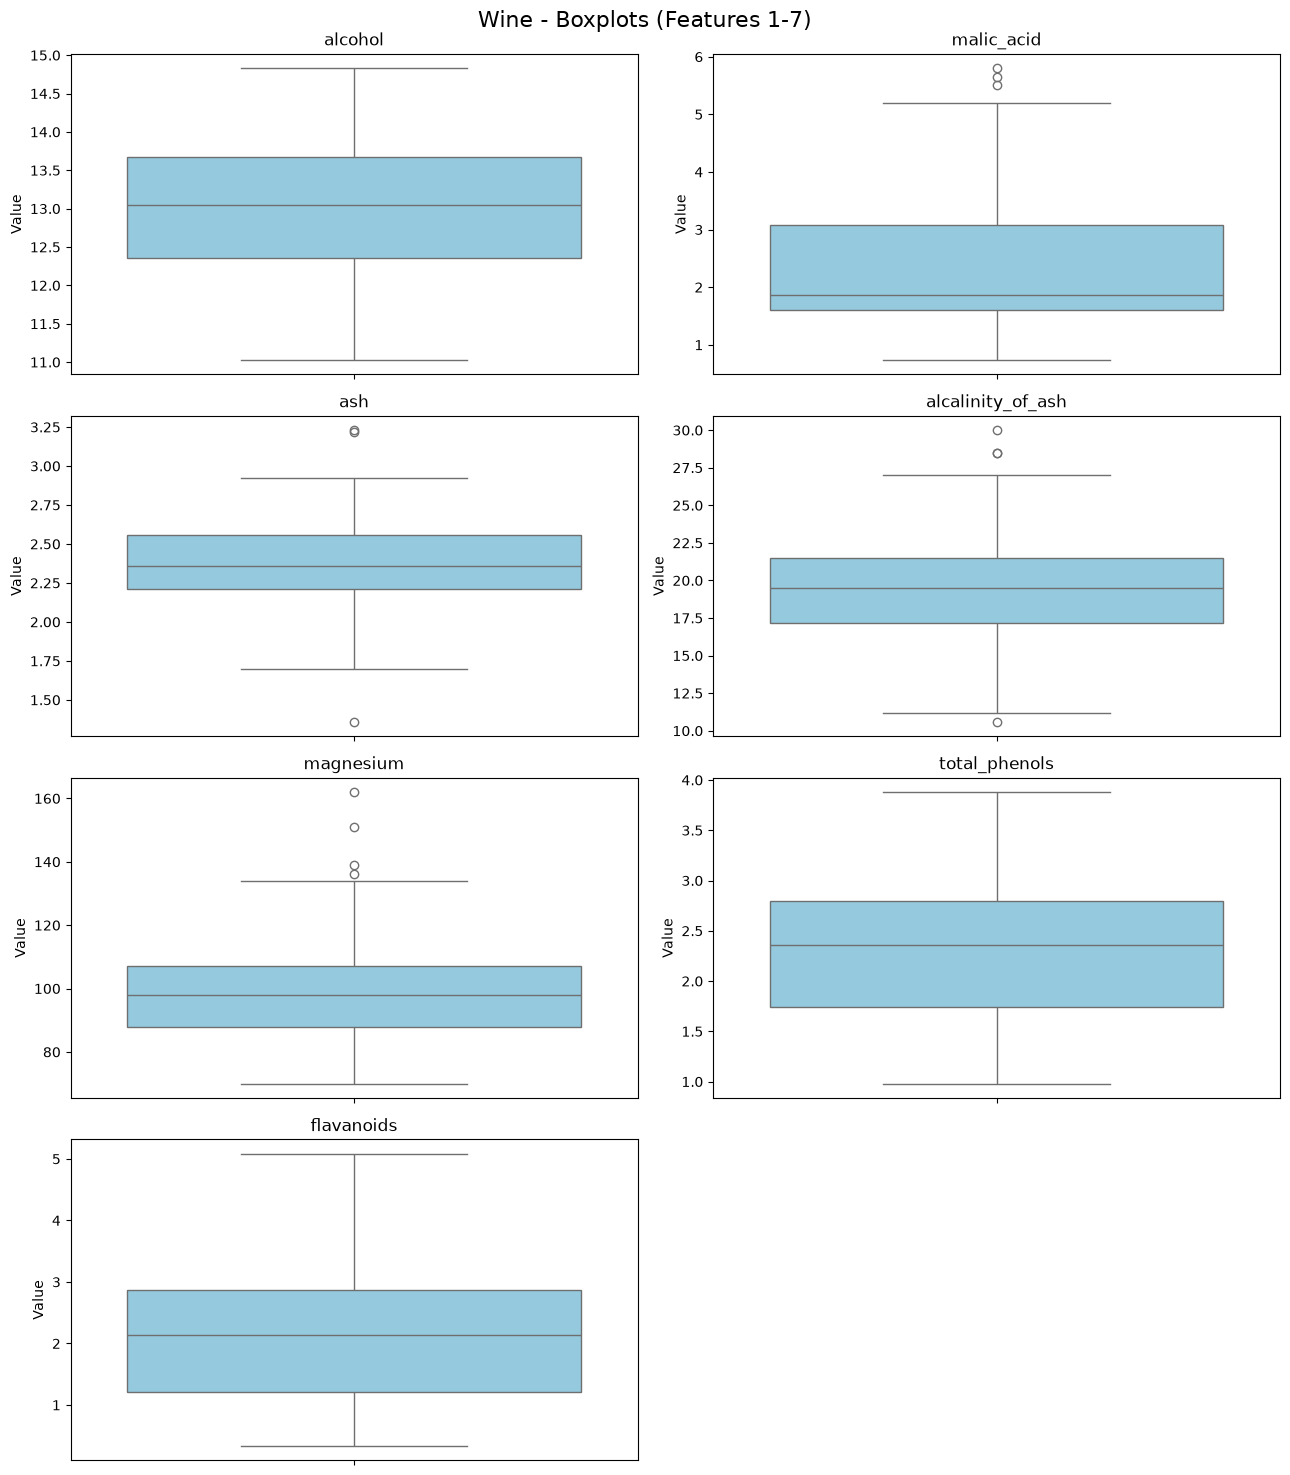

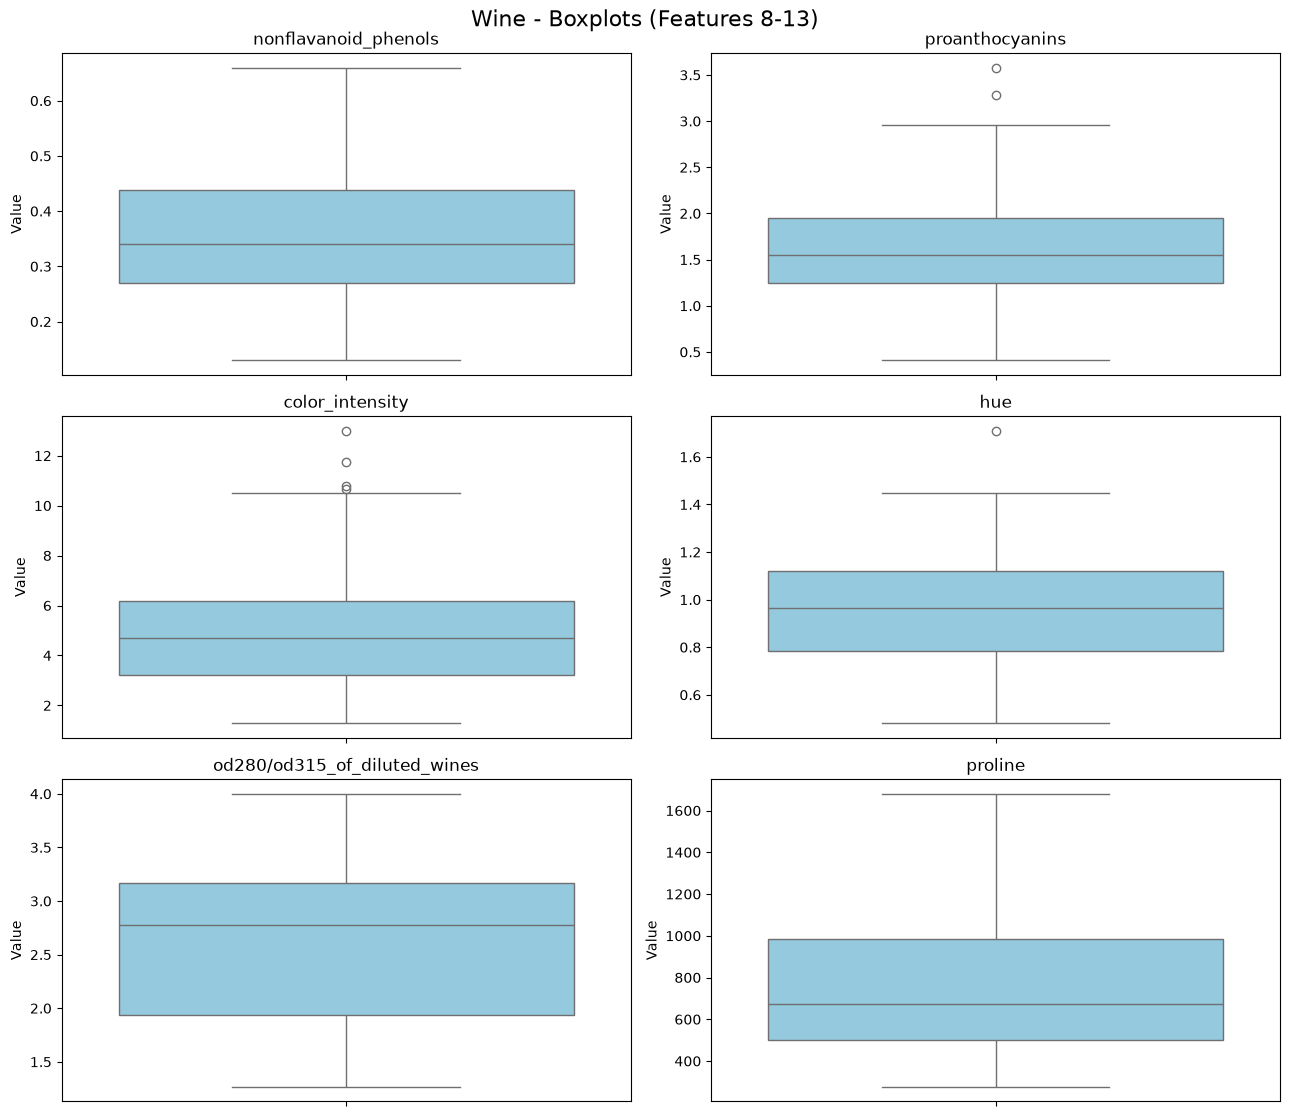

All 13 Wine features have been visualized.


In [86]:

# 3.3 Boxplots - Wine Dataset

import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs("figures", exist_ok=True)

features = X.columns.tolist()

# Divide the 13 features into groups of 7
for i in range(0, len(features), 7):

    selected_features = features[i:i+7]

    fig, axes = plt.subplots(4, 2, figsize=(13, 15))
    axes = axes.flatten()

    for j, feature in enumerate(selected_features):

        sns.boxplot(
            y=X[feature],
            ax=axes[j],
            color="skyblue"
        )

        axes[j].set_title(feature)
        axes[j].set_ylabel("Value")

    # Hide unused panels
    for j in range(len(selected_features), len(axes)):
        axes[j].set_visible(False)

    fig.suptitle(
        f"Wine - Boxplots (Features {i+1}-{i+len(selected_features)})",
        fontsize=16
    )

    plt.tight_layout()

    plt.savefig(
        f"figures/wine_boxplots_{i//7+1}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

print("All 13 Wine features have been visualized.")


**Interpretation – Exploratory Data Analysis**

The Wine dataset has 178 samples and 3 classes. Class 1 has the most samples.

The strongest correlation is between total phenols and flavanoids (r = 0.8646). Flavanoids and OD280/OD315 also have a strong correlation (r = 0.7872). Total phenols and OD280/OD315 have a positive correlation (r = 0.6999).

The boxplots show different feature ranges. For example, proline has much larger values than nonflavanoid phenols. Malic acid and color intensity also have some high outliers.

We kept all values for the next steps. Scaling is important because KNN and K-Means use distances between samples.

# 4. Splitting the Dataset
## 4.1 Fixed Test Set and Repeated Train/Validation Split
## 4.2 Verify the Splits

In [87]:

from sklearn.model_selection import train_test_split
import pandas as pd

# Required random seeds
SEEDS = [42, 52, 62]

# Reserve the fixed 20% test set once
X_remaining, X_test, y_remaining, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

# Save the original test row indices
fixed_test_indices = X_test.index.copy()

splits = {}
split_summary = []

for seed in SEEDS:

    X_train, X_val, y_train, y_val = train_test_split(
        X_remaining,
        y_remaining,
        test_size=0.125,
        stratify=y_remaining,
        random_state=seed
    )

    splits[seed] = {
        "X_train": X_train,
        "X_val": X_val,
        "y_train": y_train,
        "y_val": y_val
    }

    # Check that subsets do not overlap
    train_idx = set(X_train.index)
    val_idx = set(X_val.index)
    test_idx = set(X_test.index)

    assert train_idx.isdisjoint(val_idx)
    assert train_idx.isdisjoint(test_idx)
    assert val_idx.isdisjoint(test_idx)

    # Check that all samples are accounted for
    assert len(X_train) + len(X_val) + len(X_test) == len(X)

    # Check fixed test indices
    assert X_test.index.equals(fixed_test_indices)

    # Record the class counts for each subset
    for subset_name, subset_y in [
        ("Train", y_train),
        ("Validation", y_val),
        ("Test", y_test)
    ]:
        split_summary.append({
            "Seed": seed,
            "Subset": subset_name,
            "Samples": len(subset_y),
            "Percentage": round(len(subset_y) / len(X) * 100, 2),
            "Class 0": int((subset_y == 0).sum()),
            "Class 1": int((subset_y == 1).sum()),
            "Class 2": int((subset_y == 2).sum())
        })

# Create the nine-row split summary
split_summary_df = pd.DataFrame(split_summary)

print("WINE - SPLIT SUMMARY")
display(split_summary_df)

print("\nNUMBER OF SUMMARY ROWS:", len(split_summary_df))
assert len(split_summary_df) == 9

# Display inspectable original row indices
for seed in SEEDS:
    print(f"\nSEED {seed}")
    print("Train indices:", splits[seed]["X_train"].index.tolist())
    print("Validation indices:", splits[seed]["X_val"].index.tolist())
    print("Test indices:", X_test.index.tolist())

print("\nFixed test indices verified for all three seeds.")



WINE - SPLIT SUMMARY


,Seed,Subset,Samples,Percentage,Class 0,Class 1,Class 2
0,42,Train,124,69.66,41,50,33
1,42,Validation,18,10.11,6,7,5
2,42,Test,36,20.22,12,14,10
3,52,Train,124,69.66,41,50,33
4,52,Validation,18,10.11,6,7,5
5,52,Test,36,20.22,12,14,10
6,62,Train,124,69.66,41,50,33
7,62,Validation,18,10.11,6,7,5
8,62,Test,36,20.22,12,14,10



NUMBER OF SUMMARY ROWS: 9

SEED 42
Train indices: [163, 148, 116, 122, 115, 147, 46, 141, 57, 168, 36, 159, 103, 29, 23, 68, 101, 50, 11, 113, 114, 34, 27, 125, 165, 49, 74, 83, 162, 31, 30, 25, 44, 149, 26, 9, 63, 13, 77, 24, 142, 85, 144, 109, 41, 71, 78, 16, 92, 47, 90, 96, 150, 69, 133, 138, 91, 124, 15, 126, 139, 140, 95, 82, 56, 40, 12, 161, 99, 61, 136, 170, 156, 3, 154, 104, 37, 111, 53, 135, 76, 106, 32, 118, 119, 43, 21, 80, 65, 72, 153, 17, 67, 128, 146, 175, 55, 84, 73, 117, 70, 127, 8, 88, 87, 59, 54, 39, 45, 2, 81, 19, 174, 171, 52, 137, 167, 5, 151, 107, 131, 152, 172, 75]
Validation indices: [157, 145, 158, 110, 6, 120, 0, 89, 123, 33, 79, 35, 1, 97, 4, 86, 169, 160]
Test indices: [10, 134, 28, 121, 62, 51, 7, 66, 129, 166, 102, 143, 42, 130, 14, 108, 105, 20, 100, 38, 93, 60, 22, 18, 98, 64, 58, 132, 112, 155, 48, 176, 94, 177, 164, 173]

SEED 52
Train indices: [128, 135, 53, 27, 172, 141, 169, 11, 131, 79, 111, 83, 75, 115, 86, 84, 12, 87, 4, 89, 147, 126, 0, 55, 36,

**Interpretation – Splitting the Dataset**

We split the Wine dataset into about 70% training, 10% validation, and 20% testing.

We used three seeds: 42, 52, and 62. The test set was the same for all seeds.

We used stratified splitting to keep similar class ratios in each group.

Training data was used to train the models. Validation data was used to choose the best model. Test data was used for the final results.

# 5. Data Preprocessing and Scaling
## 5.1 Missing Values
## 5.2 Selected Scaler
## 5.3 Training-Only Scaling

In [88]:

from sklearn.preprocessing import StandardScaler
import pandas as pd

# 5.1 Check for missing values
print("TOTAL MISSING VALUES:", X.isnull().sum().sum())

assert X.isnull().sum().sum() == 0, (
    "Missing values detected: training-only imputation is required."
)

print("No missing values. Imputation is not required.")

# 5.2 Selected scaler: StandardScaler
# 5.3 Fit separately on each seed's training data

scaled_splits = {}
scalers = {}

for seed in SEEDS:

    X_train = splits[seed]["X_train"]
    X_val = splits[seed]["X_val"]

    # Create a new scaler for this seed
    scaler = StandardScaler()

    # Fit only on training features
    X_train_scaled_array = scaler.fit_transform(X_train)

    # Apply the same scaler to validation features
    X_val_scaled_array = scaler.transform(X_val)

    # Preserve feature names and original row indices
    X_train_scaled = pd.DataFrame(
        X_train_scaled_array,
        columns=X_train.columns,
        index=X_train.index
    )

    X_val_scaled = pd.DataFrame(
        X_val_scaled_array,
        columns=X_val.columns,
        index=X_val.index
    )

    scalers[seed] = scaler

    scaled_splits[seed] = {
        "X_train_scaled": X_train_scaled,
        "X_val_scaled": X_val_scaled
    }

    # Verify indices have not changed
    assert X_train_scaled.index.equals(X_train.index)
    assert X_val_scaled.index.equals(X_val.index)

    print(f"Seed {seed}: Scaling completed.")

# Prepare test features using seed-42 scaler only
X_test_scaled = pd.DataFrame(
    scalers[42].transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

# Show the required seed-42 comparison
print("\nBEFORE SCALING - SEED 42")
display(splits[42]["X_train"].head())

print("\nAFTER SCALING - SEED 42")
display(scaled_splits[42]["X_train_scaled"].head())




TOTAL MISSING VALUES: 0
No missing values. Imputation is not required.
Seed 42: Scaling completed.
Seed 52: Scaling completed.
Seed 62: Scaling completed.

BEFORE SCALING - SEED 42


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
163,12.96,3.45,2.35,18.5,106.0,1.39,0.70,0.40,0.94,5.28,0.68,1.75,675.0
148,13.32,3.24,2.38,21.5,92.0,1.93,0.76,0.45,1.25,8.42,0.55,1.62,650.0
116,11.82,1.47,1.99,20.8,86.0,1.98,1.60,0.30,1.53,1.95,0.95,3.33,495.0
122,12.42,4.43,2.73,26.5,102.0,2.20,2.13,0.43,1.71,2.08,0.92,3.12,365.0
115,11.03,1.51,2.20,21.5,85.0,2.46,2.17,0.52,2.01,1.90,1.71,2.87,407.0



AFTER SCALING - SEED 42


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
163,-0.017514,1.089178,-0.040117,-0.308405,0.433224,-1.342505,-1.322275,0.352668,-1.117639,0.125837,-1.226754,-1.223646,-0.209375
148,0.439706,0.891779,0.072941,0.609409,-0.505699,-0.490993,-1.259892,0.769946,-0.571881,1.512255,-1.811372,-1.414652,-0.291400
116,-1.465379,-0.772006,-1.396814,0.395252,-0.908094,-0.412149,-0.386537,-0.481889,-0.078939,-1.344472,-0.012548,1.097809,-0.799954
122,-0.703345,2.010370,1.391951,2.139100,0.164961,-0.065237,0.164509,0.603035,0.237953,-1.287073,-0.147460,0.789262,-1.226483
115,-2.468723,-0.734407,-0.605407,0.609409,-0.975160,0.344750,0.206097,1.354136,0.766105,-1.366549,3.405216,0.421943,-1.088682


**Interpretation – Data Preprocessing and Scaling**

There were no missing values, so we did not need to fill any data.

We used StandardScaler for all three seeds. It changes the feature values to a similar scale.

The scaler learned only from the training data. We used it to change the validation data.

For the final test, we used the scaler from seed 42. This helps prevent data leakage.

# 6. Preparing the Two Data Representations

In [89]:

# 6. Preparing the Two Data Representations - Wine

representations = {}

for seed in SEEDS:

    representations[seed] = {

        "unscaled": {
            "X_train": splits[seed]["X_train"],
            "X_val": splits[seed]["X_val"],
            "y_train": splits[seed]["y_train"],
            "y_val": splits[seed]["y_val"]
        },

        "scaled": {
            "X_train": scaled_splits[seed]["X_train_scaled"],
            "X_val": scaled_splits[seed]["X_val_scaled"],
            "y_train": splits[seed]["y_train"],
            "y_val": splits[seed]["y_val"]
        }
    }

# Verify that both representations use identical samples
for seed in SEEDS:

    unscaled = representations[seed]["unscaled"]
    scaled = representations[seed]["scaled"]

    assert unscaled["X_train"].index.equals(
        scaled["X_train"].index
    )

    assert unscaled["X_val"].index.equals(
        scaled["X_val"].index
    )

    assert unscaled["X_train"].shape == scaled["X_train"].shape
    assert unscaled["X_val"].shape == scaled["X_val"].shape

    assert unscaled["y_train"].equals(scaled["y_train"])
    assert unscaled["y_val"].equals(scaled["y_val"])

    print(f"Seed {seed}: Both representations verified.")




Seed 42: Both representations verified.
Seed 52: Both representations verified.
Seed 62: Both representations verified.


**Interpretation – Two Data Representations**

We prepared two types of data: scaled and unscaled.

Unscaled data has the original feature values. Scaled data has values changed by StandardScaler.

Both types use the same training and validation samples. This helps us compare how scaling affects the models.

# 7. Training the Classification Models
## 7.1 Required Experiments
## 7.2 Recording the Experiments

# 8. Measuring Validation Performance
## 8.1 Required Metrics

In [90]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

import sklearn
import numpy as np
import pandas as pd

# Required parameter settings
tree_depths = [2, 3, 5, 10, None]
knn_neighbors = [1, 3, 5, 7, 11]

# Store results and fitted models
classifier_results = []
fitted_models = {}

# Wine uses multiclass ROC-AUC
def calculate_metrics(y_true, y_pred, probabilities, classes):

    expected_classes = np.array([0, 1, 2])

    assert np.array_equal(classes, expected_classes), (
        "Probability columns must match classes 0, 1, 2."
    )

    return {
        "accuracy": accuracy_score(y_true, y_pred),

        "macro_precision": precision_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),

        "macro_recall": recall_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),

        "macro_f1": f1_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),

        "roc_auc": roc_auc_score(
            y_true,
            probabilities,
            labels=expected_classes,
            multi_class="ovr",
            average="macro"
        )
    }


# Train models for all seeds and representations
for seed in SEEDS:

    for representation in ["unscaled", "scaled"]:

        data = representations[seed][representation]

        X_train = data["X_train"]
        X_val = data["X_val"]
        y_train = data["y_train"]
        y_val = data["y_val"]

        configurations = []

        # Decision Tree
        for depth in tree_depths:

            configurations.append((
                "decision_tree",
                f"depth{depth}",
                DecisionTreeClassifier(
                    max_depth=depth,
                    random_state=seed
                )
            ))

        # K-Nearest Neighbors
        for k in knn_neighbors:

            configurations.append((
                "knn",
                f"k{k}",
                KNeighborsClassifier(
                    n_neighbors=k,
                    weights="uniform",
                    metric="euclidean"
                )
            ))

        # Gaussian Naive Bayes
        configurations.append((
            "gaussian_nb",
            "default",
            GaussianNB()
        ))

        # Fit and evaluate all configurations
        for algorithm, parameter, model in configurations:

            experiment_id = (
                f"wine_{algorithm}_"
                f"{representation}_{parameter}_s{seed}"
            )

            # Fit only on training data
            model.fit(X_train, y_train)

            train_predictions = model.predict(X_train)
            val_predictions = model.predict(X_val)

            val_probabilities = model.predict_proba(X_val)

            # Training metrics
            train_accuracy = accuracy_score(
                y_train,
                train_predictions
            )

            train_macro_f1 = f1_score(
                y_train,
                train_predictions,
                average="macro",
                zero_division=0
            )

            # Identify undefined per-class precision
            # or recall before zero replacement
            cm = confusion_matrix(
                y_val,
                val_predictions,
                labels=[0, 1, 2]
            )

            undefined_precision = [
                int(c)
                for c in range(3)
                if cm[:, c].sum() == 0
            ]

            undefined_recall = [
                int(c)
                for c in range(3)
                if cm[c, :].sum() == 0
            ]

            # Validation metrics
            validation_metrics = calculate_metrics(
                y_val,
                val_predictions,
                val_probabilities,
                model.classes_
            )

            classifier_results.append({
                "dataset": "wine",
                "experiment_id": experiment_id,
                "seed": seed,
                "algorithm": algorithm,
                "representation": representation,
                "parameter": parameter,
                "train_accuracy": train_accuracy,
                "train_macro_f1": train_macro_f1,
                "val_accuracy": validation_metrics["accuracy"],
                "val_macro_precision": validation_metrics["macro_precision"],
                "val_macro_recall": validation_metrics["macro_recall"],
                "val_macro_f1": validation_metrics["macro_f1"],
                "val_roc_auc": validation_metrics["roc_auc"],
                "undefined_precision_classes": str(undefined_precision),
                "undefined_recall_classes": str(undefined_recall)
            })

            # Retain fitted models for final evaluation
            fitted_models[experiment_id] = model


# Create run-level results table
classifier_runs_df = pd.DataFrame(classifier_results)

print("WINE - CLASSIFIER RUN RESULTS")
display(classifier_runs_df)

print("\nTOTAL CLASSIFIER RUNS:", len(classifier_runs_df))

assert len(classifier_runs_df) == 66
assert classifier_runs_df["experiment_id"].is_unique

print("\nAll 66 Wine classifier runs completed successfully.")

# Show any undefined class metrics
undefined_runs = classifier_runs_df[
    (classifier_runs_df["undefined_precision_classes"] != "[]") |
    (classifier_runs_df["undefined_recall_classes"] != "[]")
]

print("\nRUNS WITH UNDEFINED PER-CLASS METRICS")
display(undefined_runs[
    [
        "experiment_id",
        "undefined_precision_classes",
        "undefined_recall_classes"
    ]
])

# Record package versions
print("\nSCIKIT-LEARN VERSION:", sklearn.__version__)
print("NUMPY VERSION:", np.__version__)
print("PANDAS VERSION:", pd.__version__)


WINE - CLASSIFIER RUN RESULTS


,dataset,experiment_id,seed,algorithm,representation,parameter,train_accuracy,train_macro_f1,val_accuracy,val_macro_precision,val_macro_recall,val_macro_f1,val_roc_auc,undefined_precision_classes,undefined_recall_classes
0,wine,wine_decision_tree_unscaled_depth2_s42,42,decision_tree,unscaled,depth2,0.935484,0.929694,0.833333,0.863095,0.811111,0.817521,0.910596,[],[]
1,wine,wine_decision_tree_unscaled_depth3_s42,42,decision_tree,unscaled,depth3,0.991935,0.992584,0.944444,0.958333,0.944444,0.947475,0.968645,[],[]
2,wine,wine_decision_tree_unscaled_depth5_s42,42,decision_tree,unscaled,depth5,1.000000,1.000000,0.944444,0.958333,0.944444,0.947475,0.957071,[],[]
3,wine,wine_decision_tree_unscaled_depth10_s42,42,decision_tree,unscaled,depth10,1.000000,1.000000,0.944444,0.958333,0.944444,0.947475,0.957071,[],[]
4,wine,wine_decision_tree_unscaled_depthNone_s42,42,decision_tree,unscaled,depthNone,1.000000,1.000000,0.944444,0.958333,0.944444,0.947475,0.957071,[],[]
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
61,wine,wine_knn_scaled_k3_s62,62,knn,scaled,k3,0.959677,0.960888,0.888889,0.896825,0.904762,0.888500,1.000000,[],[]
62,wine,wine_knn_scaled_k5_s62,62,knn,scaled,k5,0.975806,0.975871,0.944444,0.944444,0.952381,0.944056,1.000000,[],[]
63,wine,wine_knn_scaled_k7_s62,62,knn,scaled,k7,0.967742,0.968371,0.944444,0.944444,0.952381,0.944056,1.000000,[],[]
64,wine,wine_knn_scaled_k11_s62,62,knn,scaled,k11,0.967742,0.968371,0.944444,0.944444,0.952381,0.944056,1.000000,[],[]



TOTAL CLASSIFIER RUNS: 66

All 66 Wine classifier runs completed successfully.

RUNS WITH UNDEFINED PER-CLASS METRICS


,experiment_id,undefined_precision_classes,undefined_recall_classes



SCIKIT-LEARN VERSION: 1.9.1
NUMPY VERSION: 2.5.4
PANDAS VERSION: 3.1.1


## 8.2 Comparison Tables and Model Selection

In [91]:

import os
import pandas as pd

os.makedirs("results", exist_ok=True)
os.makedirs("figures", exist_ok=True)

metric_columns = [
    "train_accuracy",
    "train_macro_f1",
    "val_accuracy",
    "val_macro_precision",
    "val_macro_recall",
    "val_macro_f1",
    "val_roc_auc"
]

group_columns = [
    "dataset",
    "algorithm",
    "representation",
    "parameter"
]

# Mean and sample standard deviation across three seeds
classifier_summary_df = (
    classifier_runs_df
    .groupby(group_columns, as_index=False)[metric_columns]
    .agg(["mean", "std"])
)

# Flatten column names
classifier_summary_df.columns = [
    "_".join(col).strip("_")
    if isinstance(col, tuple) else col
    for col in classifier_summary_df.columns
]

# Unique configuration identifier
classifier_summary_df["configuration_id"] = (
    classifier_summary_df["dataset"] + "_" +
    classifier_summary_df["algorithm"] + "_" +
    classifier_summary_df["representation"] + "_" +
    classifier_summary_df["parameter"]
)

# Required model selection rules
classifier_summary_df = classifier_summary_df.sort_values(
    by=[
        "val_macro_f1_mean",
        "val_accuracy_mean",
        "val_macro_f1_std",
        "configuration_id"
    ],
    ascending=[False, False, True, True]
).reset_index(drop=True)

print("WINE - CLASSIFIER SUMMARY")
display(classifier_summary_df.round(4))

print("\nNUMBER OF CONFIGURATIONS:", len(classifier_summary_df))
assert len(classifier_summary_df) == 22

# Freeze the selected configuration
best_configuration = classifier_summary_df.iloc[0].copy()

print("\nSELECTED CONFIGURATION")
print("Algorithm:", best_configuration["algorithm"])
print("Representation:", best_configuration["representation"])
print("Parameter:", best_configuration["parameter"])
print(
    "Mean Validation Macro-F1:",
    round(best_configuration["val_macro_f1_mean"], 4)
)
print(
    "Validation Macro-F1 Std:",
    round(best_configuration["val_macro_f1_std"], 4)
)

# Save temporary Wine result files
classifier_runs_df.to_csv(
    "results/wine_classifier_runs.csv",
    index=False
)

classifier_summary_df.to_csv(
    "results/wine_classifier_summary.csv",
    index=False
)




WINE - CLASSIFIER SUMMARY


,dataset,algorithm,representation,parameter,train_accuracy_mean,train_accuracy_std,train_macro_f1_mean,train_macro_f1_std,val_accuracy_mean,val_accuracy_std,val_macro_precision_mean,val_macro_precision_std,val_macro_recall_mean,val_macro_recall_std,val_macro_f1_mean,val_macro_f1_std,val_roc_auc_mean,val_roc_auc_std,configuration_id
0,wine,knn,scaled,k11,0.9651,0.0047,0.9656,0.0048,0.9815,0.0321,0.9815,0.0321,0.9841,0.0275,0.9814,0.0323,1.0000,0.0000,wine_knn_scaled_k11
1,wine,knn,scaled,k5,0.9758,0.0000,0.9762,0.0005,0.9815,0.0321,0.9815,0.0321,0.9841,0.0275,0.9814,0.0323,1.0000,0.0000,wine_knn_scaled_k5
2,wine,knn,scaled,k7,0.9597,0.0081,0.9603,0.0080,0.9815,0.0321,0.9815,0.0321,0.9841,0.0275,0.9814,0.0323,1.0000,0.0000,wine_knn_scaled_k7
3,wine,knn,scaled,k1,1.0000,0.0000,1.0000,0.0000,0.9630,0.0321,0.9683,0.0275,0.9683,0.0275,0.9658,0.0296,0.9749,0.0218,wine_knn_scaled_k1
4,wine,gaussian_nb,scaled,default,0.9839,0.0000,0.9840,0.0005,0.9630,0.0321,0.9676,0.0289,0.9656,0.0300,0.9638,0.0314,1.0000,0.0000,wine_gaussian_nb_scaled_default
5,wine,gaussian_nb,unscaled,default,0.9839,0.0000,0.9840,0.0005,0.9630,0.0321,0.9676,0.0289,0.9656,0.0300,0.9638,0.0314,1.0000,0.0000,wine_gaussian_nb_unscaled_default
6,wine,decision_tree,scaled,depth10,1.0000,0.0000,1.0000,0.0000,0.9444,0.0556,0.9614,0.0371,0.9407,0.0612,0.9462,0.0545,0.9552,0.0457,wine_decision_tree_scaled_depth10
7,wine,decision_tree,scaled,depth3,0.9919,0.0000,0.9926,0.0000,0.9444,0.0556,0.9614,0.0371,0.9407,0.0612,0.9462,0.0545,0.9611,0.0431,wine_decision_tree_scaled_depth3
8,wine,decision_tree,scaled,depth5,1.0000,0.0000,1.0000,0.0000,0.9444,0.0556,0.9614,0.0371,0.9407,0.0612,0.9462,0.0545,0.9552,0.0457,wine_decision_tree_scaled_depth5
9,wine,decision_tree,scaled,depthNone,1.0000,0.0000,1.0000,0.0000,0.9444,0.0556,0.9614,0.0371,0.9407,0.0612,0.9462,0.0545,0.9552,0.0457,wine_decision_tree_scaled_depthNone



NUMBER OF CONFIGURATIONS: 22

SELECTED CONFIGURATION
Algorithm: knn
Representation: scaled
Parameter: k11
Mean Validation Macro-F1: 0.9814
Validation Macro-F1 Std: 0.0323


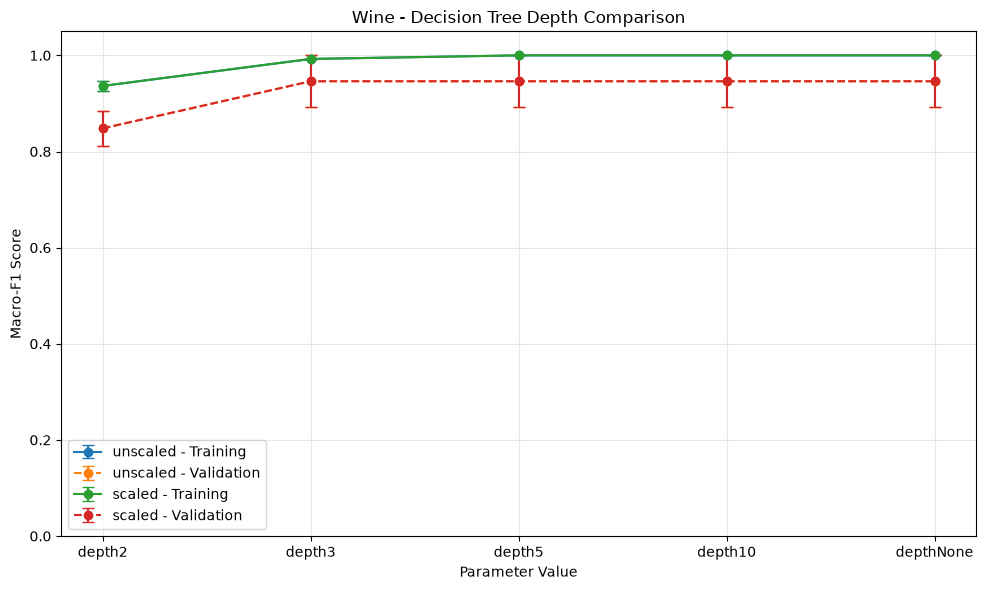

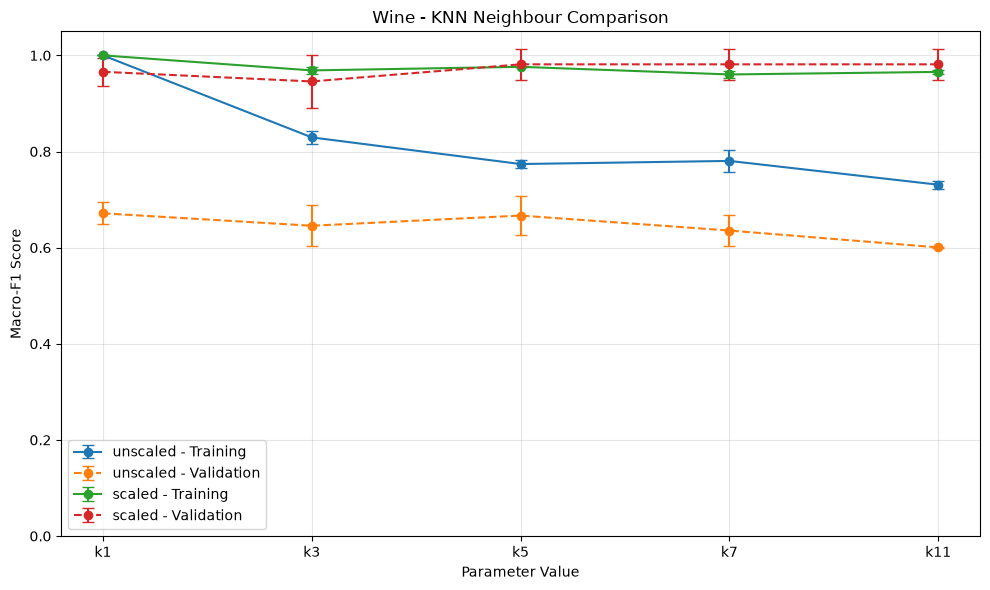

In [92]:

import matplotlib.pyplot as plt
import numpy as np

def plot_parameter_comparison(
    algorithm, parameters, title, filename
):
    fig, ax = plt.subplots(figsize=(10, 6))

    for representation in ["unscaled", "scaled"]:

        subset = classifier_summary_df[
            (classifier_summary_df["algorithm"] == algorithm) &
            (classifier_summary_df["representation"] == representation)
        ].copy()

        subset["parameter"] = pd.Categorical(
            subset["parameter"],
            categories=parameters,
            ordered=True
        )

        subset = subset.sort_values("parameter")
        x = np.arange(len(subset))

        for metric, linestyle, label in [
            ("train_macro_f1", "-", "Training"),
            ("val_macro_f1", "--", "Validation")
        ]:
            ax.errorbar(
                x,
                subset[f"{metric}_mean"],
                yerr=subset[f"{metric}_std"],
                marker="o",
                linestyle=linestyle,
                capsize=4,
                label=f"{representation} - {label}"
            )

    ax.set_xticks(range(len(parameters)))
    ax.set_xticklabels(parameters)
    ax.set_xlabel("Parameter Value")
    ax.set_ylabel("Macro-F1 Score")
    ax.set_ylim(0, 1.05)
    ax.set_title(title)
    ax.legend()
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()


# Decision Tree comparison
plot_parameter_comparison(
    algorithm="decision_tree",
    parameters=[
        "depth2", "depth3", "depth5",
        "depth10", "depthNone"
    ],
    title="Wine - Decision Tree Depth Comparison",
    filename="figures/wine_tree_depth_comparison.png"
)

# KNN comparison
plot_parameter_comparison(
    algorithm="knn",
    parameters=["k1", "k3", "k5", "k7", "k11"],
    title="Wine - KNN Neighbour Comparison",
    filename="figures/wine_knn_comparison.png"
)




**Interpretation – Classification and Validation**

We trained 66 models using Decision Tree, KNN, and Gaussian Naive Bayes.

We used three seeds and both scaled and unscaled data.

We compared the models using validation scores. The best model was scaled KNN with k=11.

Its mean validation macro-F1 score was 0.9814, and the standard deviation was 0.0323.

We selected this model using validation results, not test results.


**Scaling Effect**

KNN was the most affected algorithm by scaling. Its average validation macro-F1 increased by 0.3272.

Decision Tree and Gaussian Naive Bayes did not change.

**Decision Tree Depth Effect**

The mean validation macro-F1 increased from 0.8481 at depth 2 to 0.9462 at depth 3.

Depth 3, 5, 10, and None gave the same score.

Scaling did not change the Decision Tree results. Increasing tree depth did not always improve the score.

**KNN Neighbour Count Effect**

The best scaled KNN scores were with k=5, k=7, and k=11. All three had a mean validation macro-F1 of 0.9814.

The unscaled KNN scores were much lower. For k=11, the unscaled score was 0.6005.

More neighbours did not always give better results. Scaling helped KNN a lot.

**Seed Variability**

The results changed between the three seeds.

For Wine, the average standard deviation was 0.0406. The minimum was 0.0010, and the maximum was 0.0558.

This shows that different training and validation splits can change model performance.

**Training and Validation Gap**

The training macro-F1 was 0.9656, and the validation macro-F1 was 0.9814.

The gap was -0.0158. The validation score was slightly higher than the training score. This can happen with small validation sets.

# 9. Evaluating the Selected Model on the Test Set
## 9.1 Final Performance Metrics
## 9.2 Confusion Matrix and Manual Metric Calculation
## 9.3 ROC Curves
## 9.4 Error Interpretation

WINE - FINAL TEST RESULTS
Selected model: wine_knn_scaled_k11_s42
Evaluation seed: 42
accuracy: 1.0000
macro_precision: 1.0000
macro_recall: 1.0000
macro_f1: 1.0000
roc_auc: 1.0000

CLASSIFICATION REPORT
              precision    recall  f1-score   support

     Class 0       1.00      1.00      1.00        12
     Class 1       1.00      1.00      1.00        14
     Class 2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36



,dataset,selected_configuration,evaluation_seed,mean_val_macro_f1,std_val_macro_f1,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1,test_roc_auc
0,wine,wine_knn_scaled_k11,42,0.9814,0.0323,1.0,1.0,1.0,1.0,1.0


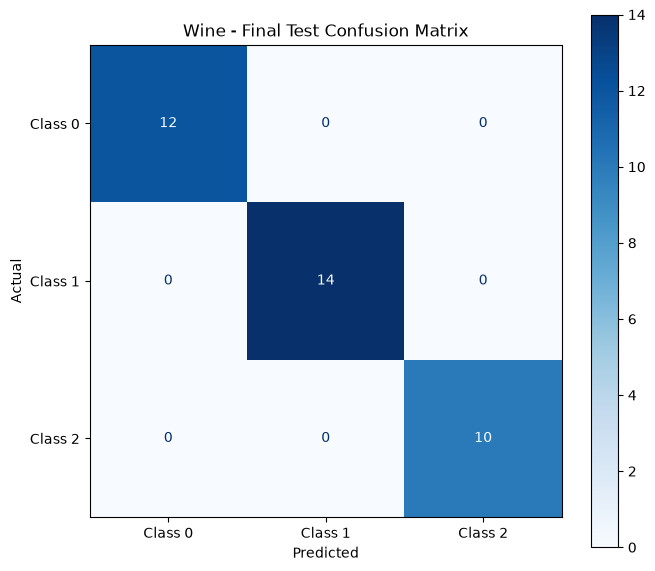


MANUAL METRIC CHECK - CLASS 0
TP: 12
FP: 0
FN: 0
TN: 24
Class 0 Precision: 1.0
Class 0 Recall: 1.0
Class 0 F1: 1.0


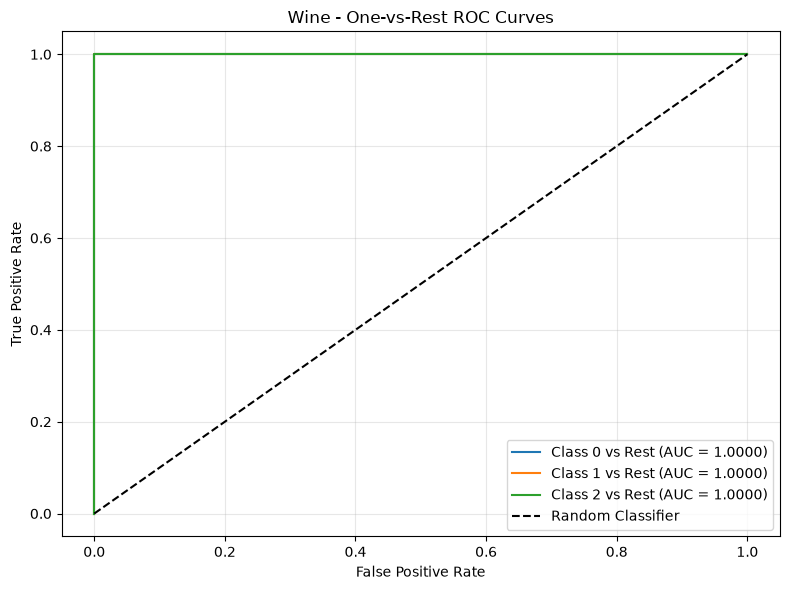


CLASS-SPECIFIC ROC-AUC VALUES
Class 0: 1.0000
Class 1: 1.0000
Class 2: 1.0000
Macro OvR ROC-AUC: 1.0

MISCLASSIFIED TEST SAMPLES
Total errors: 0


,actual,predicted


No test misclassifications. This does not establish perfect generalisation.


In [93]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)
from sklearn.preprocessing import label_binarize
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

os.makedirs("results", exist_ok=True)
os.makedirs("figures", exist_ok=True)

# 9.1 Final Test Evaluation
# Use the selected configuration fitted with seed 42

selected_model_id = (
    f"wine_{best_configuration['algorithm']}_"
    f"{best_configuration['representation']}_"
    f"{best_configuration['parameter']}_s42"
)

selected_model = fitted_models[selected_model_id]

if best_configuration["representation"] == "scaled":
    X_final_test = X_test_scaled
else:
    X_final_test = X_test

# Do not fit the model again
y_test_pred = selected_model.predict(X_final_test)
y_test_proba = selected_model.predict_proba(X_final_test)

assert np.array_equal(
    selected_model.classes_,
    np.array([0, 1, 2])
)

test_metrics = calculate_metrics(
    y_test,
    y_test_pred,
    y_test_proba,
    selected_model.classes_
)

print("WINE - FINAL TEST RESULTS")
print("Selected model:", selected_model_id)
print("Evaluation seed: 42")

for metric, value in test_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nCLASSIFICATION REPORT")

report = classification_report(
    y_test,
    y_test_pred,
    labels=[0, 1, 2],
    target_names=["Class 0", "Class 1", "Class 2"],
    zero_division=0
)

print(report)

# Save final test results
classifier_test_df = pd.DataFrame([{
    "dataset": "wine",
    "selected_configuration": best_configuration["configuration_id"],
    "evaluation_seed": 42,
    "mean_val_macro_f1": best_configuration["val_macro_f1_mean"],
    "std_val_macro_f1": best_configuration["val_macro_f1_std"],
    "test_accuracy": test_metrics["accuracy"],
    "test_macro_precision": test_metrics["macro_precision"],
    "test_macro_recall": test_metrics["macro_recall"],
    "test_macro_f1": test_metrics["macro_f1"],
    "test_roc_auc": test_metrics["roc_auc"]
}])

display(classifier_test_df.round(4))

classifier_test_df.to_csv(
    "results/wine_classifier_test.csv",
    index=False
)


# 9.2 Confusion Matrix
cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=[0, 1, 2]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Class 0", "Class 1", "Class 2"]
)

fig, ax = plt.subplots(figsize=(7, 6))

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d"
)

ax.set_title("Wine - Final Test Confusion Matrix")
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")

plt.tight_layout()
plt.savefig(
    "figures/wine_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# Manually calculate metrics for Class 0
class_id = 0

TP = cm[class_id, class_id]
FN = cm[class_id, :].sum() - TP
FP = cm[:, class_id].sum() - TP
TN = cm.sum() - TP - FN - FP

manual_precision = (
    TP / (TP + FP) if TP + FP > 0 else np.nan
)

manual_recall = (
    TP / (TP + FN) if TP + FN > 0 else np.nan
)

manual_f1 = (
    2 * TP / (2 * TP + FP + FN)
    if 2 * TP + FP + FN > 0 else np.nan
)

print("\nMANUAL METRIC CHECK - CLASS 0")
print("TP:", TP)
print("FP:", FP)
print("FN:", FN)
print("TN:", TN)

print("Class 0 Precision:", manual_precision)
print("Class 0 Recall:", manual_recall)
print("Class 0 F1:", manual_f1)


# 9.3 ROC Curves: One-vs-Rest for all three classes

y_test_binary = label_binarize(
    y_test,
    classes=[0, 1, 2]
)

plt.figure(figsize=(8, 6))

class_auc_values = []

for class_id in range(3):

    fpr, tpr, thresholds = roc_curve(
        y_test_binary[:, class_id],
        y_test_proba[:, class_id]
    )

    class_auc = roc_auc_score(
        y_test_binary[:, class_id],
        y_test_proba[:, class_id]
    )

    class_auc_values.append(class_auc)

    plt.plot(
        fpr,
        tpr,
        label=f"Class {class_id} vs Rest (AUC = {class_auc:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Wine - One-vs-Rest ROC Curves")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    "figures/wine_roc_curves.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("\nCLASS-SPECIFIC ROC-AUC VALUES")

for class_id, auc_value in enumerate(class_auc_values):
    print(f"Class {class_id}: {auc_value:.4f}")

print("Macro OvR ROC-AUC:",
      round(test_metrics["roc_auc"], 4))


# 9.4 Error Analysis

errors = pd.DataFrame({
    "actual": np.asarray(y_test),
    "predicted": y_test_pred
}, index=X_test.index)

errors = errors[
    errors["actual"] != errors["predicted"]
]

print("\nMISCLASSIFIED TEST SAMPLES")
print("Total errors:", len(errors))

display(errors)

if len(errors) > 0:

    first_error_index = errors.index[0]

    print("\nFIRST ERROR - ORIGINAL ROW INDEX:",
          first_error_index)

    display(X_test.loc[[first_error_index]])

else:
    print(
        "No test misclassifications. "
        "This does not establish perfect generalisation."
    )


**Interpretation – Final Test Evaluation**

We tested the scaled KNN model with k=11 using seed 42.

The test accuracy, macro-F1, and ROC-AUC were all 1.0000.

The model predicted all 36 test samples correctly. There were no wrong predictions.

The test score was higher than the mean validation macro-F1 score of 0.9814.

However, this does not mean the model will always be perfect on new data.

# 10. K-Means Clustering
## 10.1 Fit the Clustering Model
## 10.2 Final Cluster Evaluation
## 10.3 Cluster Visualisation and Interpretation

WINE - K-MEANS RUN RESULTS


,dataset,experiment_id,seed,representation,n_clusters,n_init,train_inertia,val_ari,val_silhouette
0,wine,wine_kmeans_unscaled_s42,42,unscaled,3,10,1.350496e+06,0.2828,0.4870
1,wine,wine_kmeans_scaled_s42,42,scaled,3,10,8.747391e+02,1.0000,0.2516
2,wine,wine_kmeans_unscaled_s52,52,unscaled,3,10,1.303675e+06,0.4006,0.5559
3,wine,wine_kmeans_scaled_s52,52,scaled,3,10,8.904355e+02,1.0000,0.3010
4,wine,wine_kmeans_unscaled_s62,62,unscaled,3,10,1.390754e+06,0.4006,0.6867
5,wine,wine_kmeans_scaled_s62,62,scaled,3,10,8.722466e+02,1.0000,0.2726



WINE - K-MEANS SUMMARY


,dataset,representation,inertia_mean,inertia_std,val_ari_mean,val_ari_std,val_silhouette_mean,val_silhouette_std,valid_silhouette_seeds
0,wine,scaled,8.791404e+02,9.8609,1.0000,0.000,0.2751,0.0248,3
1,wine,unscaled,1.348308e+06,43580.9098,0.3613,0.068,0.5765,0.1014,3



TEST RESULTS - UNSCALED
Test ARI: 0.3733
Test Silhouette: 0.4929

CLUSTER COUNTS
0    14
1    10
2    12
Name: count, dtype: int64

CLASS VERSUS CLUSTER TABLE


Cluster ID,0,1,2
True Class,,,
0,2,10,0
1,5,0,9
2,7,0,3


... (2 outputs left out)


FINAL K-MEANS TEST TABLE


,dataset,representation,evaluation_seed,test_cluster_counts,test_ari,test_silhouette
0,wine,unscaled,42,"{0: 14, 1: 10, 2: 12}",0.3733,0.4929
1,wine,scaled,42,"{0: 13, 1: 13, 2: 10}",0.9088,0.2711



SELECTED FEATURES - SEED 42 TRAINING DATA


,alcohol,color_intensity
count,124.000000,124.000000
mean,12.973790,4.995000
std,0.790561,2.274017
min,11.030000,1.280000
25%,12.370000,3.147500
50%,12.975000,4.690000
75%,13.565000,6.212500
max,14.830000,11.750000


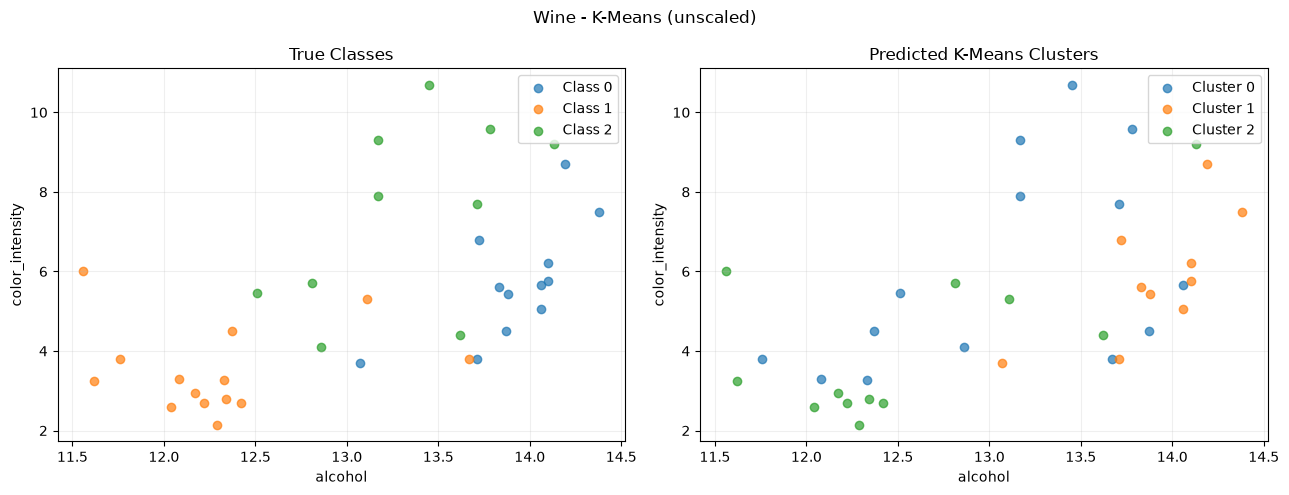

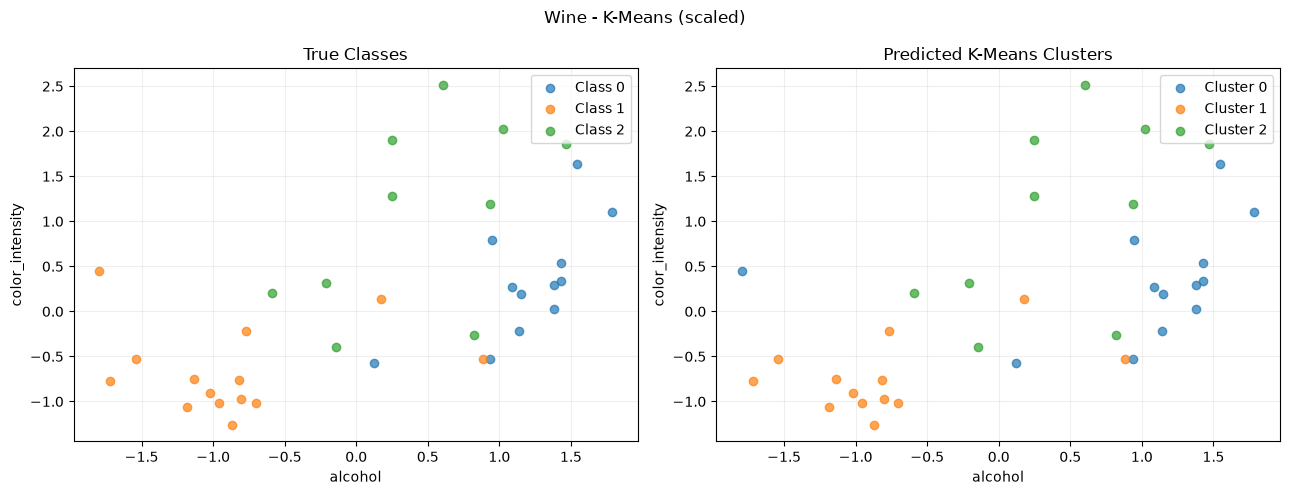

In [94]:

from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

os.makedirs("results", exist_ok=True)
os.makedirs("figures", exist_ok=True)

kmeans_models = {}
kmeans_results = {}

def safe_silhouette(features, clusters):
    n_clusters = len(np.unique(clusters))
    if 2 <= n_clusters < len(features):
        return silhouette_score(features, clusters)
    return np.nan

# 10.1 Fit six K-Means models
run_records = []

for seed in SEEDS:
    for representation in ["unscaled", "scaled"]:

        data = representations[seed][representation]
        X_train_km = data["X_train"]
        X_val_km = data["X_val"]
        y_val_km = data["y_val"]

        model = KMeans(
            n_clusters=3,
            random_state=seed,
            n_init=10
        )

        model.fit(X_train_km)

        val_clusters = model.predict(X_val_km)

        run_id = f"wine_kmeans_{representation}_s{seed}"

        kmeans_models[(seed, representation)] = model

        run_records.append({
            "dataset": "wine",
            "experiment_id": run_id,
            "seed": seed,
            "representation": representation,
            "n_clusters": 3,
            "n_init": 10,
            "train_inertia": model.inertia_,
            "val_ari": adjusted_rand_score(
                y_val_km, val_clusters
            ),
            "val_silhouette": safe_silhouette(
                X_val_km, val_clusters
            )
        })

kmeans_runs_df = pd.DataFrame(run_records)

print("WINE - K-MEANS RUN RESULTS")
display(kmeans_runs_df.round(4))

assert len(kmeans_runs_df) == 6

# Across-seed summary
kmeans_summary_df = (
    kmeans_runs_df
    .groupby(["dataset", "representation"], as_index=False)
    .agg(
        inertia_mean=("train_inertia", "mean"),
        inertia_std=("train_inertia", "std"),
        val_ari_mean=("val_ari", "mean"),
        val_ari_std=("val_ari", "std"),
        val_silhouette_mean=("val_silhouette", "mean"),
        val_silhouette_std=("val_silhouette", "std"),
        valid_silhouette_seeds=("val_silhouette", "count")
    )
)

print("\nWINE - K-MEANS SUMMARY")
display(kmeans_summary_df.round(4))

assert len(kmeans_summary_df) == 2

kmeans_runs_df.to_csv(
    "results/wine_kmeans_runs.csv", index=False
)
kmeans_summary_df.to_csv(
    "results/wine_kmeans_summary.csv", index=False
)

# 10.2 Seed-42 final test evaluation
test_records = {}

for representation in ["unscaled", "scaled"]:

    model = kmeans_models[(42, representation)]

    X_test_km = (
        X_test_scaled if representation == "scaled"
        else X_test
    )

    predicted_clusters = model.predict(X_test_km)

    test_ari = adjusted_rand_score(
        y_test, predicted_clusters
    )

    test_silhouette = safe_silhouette(
        X_test_km, predicted_clusters
    )

    cluster_counts = pd.Series(
        predicted_clusters
    ).value_counts().sort_index()

    contingency = pd.crosstab(
        pd.Series(y_test.to_numpy(), name="True Class"),
        pd.Series(predicted_clusters, name="Cluster ID")
    ).reindex(
        index=[0, 1, 2],
        columns=[0, 1, 2],
        fill_value=0
    )

    assert contingency.to_numpy().sum() == len(y_test)

    print(f"\nTEST RESULTS - {representation.upper()}")
    print("Test ARI:", round(test_ari, 4))
    print(
        "Test Silhouette:",
        round(test_silhouette, 4)
        if np.isfinite(test_silhouette) else "N/A"
    )

    print("\nCLUSTER COUNTS")
    print(cluster_counts)

    print("\nCLASS VERSUS CLUSTER TABLE")
    display(contingency)

    test_records[representation] = {
        "dataset": "wine",
        "representation": representation,
        "evaluation_seed": 42,
        "test_cluster_counts": str(cluster_counts.to_dict()),
        "test_ari": test_ari,
        "test_silhouette": test_silhouette
    }

kmeans_test_df = pd.DataFrame(test_records.values())

print("\nFINAL K-MEANS TEST TABLE")
display(kmeans_test_df.round(4))

kmeans_test_df.to_csv(
    "results/wine_kmeans_test.csv", index=False
)

# 10.3 Two-feature cluster visualisations
# Both features are original Wine features
selected_features = ["alcohol", "color_intensity"]

print("\nSELECTED FEATURES - SEED 42 TRAINING DATA")
display(
    splits[42]["X_train"][selected_features].describe()
)

for representation in ["unscaled", "scaled"]:

    model = kmeans_models[(42, representation)]

    X_test_km = (
        X_test_scaled if representation == "scaled"
        else X_test
    )

    predicted_clusters = model.predict(X_test_km)

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    # Panel 1: True classes
    for class_id in [0, 1, 2]:
        mask = y_test.to_numpy() == class_id

        axes[0].scatter(
            X_test_km.loc[mask, selected_features[0]],
            X_test_km.loc[mask, selected_features[1]],
            label=f"Class {class_id}",
            alpha=0.7
        )

    axes[0].set_title("True Classes")
    axes[0].legend()

    # Panel 2: K-Means cluster IDs
    for cluster_id in np.unique(predicted_clusters):
        mask = predicted_clusters == cluster_id

        axes[1].scatter(
            X_test_km.loc[mask, selected_features[0]],
            X_test_km.loc[mask, selected_features[1]],
            label=f"Cluster {cluster_id}",
            alpha=0.7
        )

    axes[1].set_title("Predicted K-Means Clusters")
    axes[1].legend()

    for ax in axes:
        ax.set_xlabel(selected_features[0])
        ax.set_ylabel(selected_features[1])
        ax.grid(alpha=0.2)

    fig.suptitle(f"Wine - K-Means ({representation})")

    plt.tight_layout()
    plt.savefig(
        f"figures/wine_kmeans_{representation}.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()



**Interpretation – K-Means Clustering**

We trained 6 K-Means models using three seeds and both scaled and unscaled data.

The unscaled model had a test ARI of 0.3733 and a silhouette score of 0.4929.

The scaled model had a higher ARI of 0.9088, but a lower silhouette score of 0.2711.

After scaling, the clusters were closer to the real Wine classes. Only one sample was in a different cluster from most samples of its class.

K-Means did not use class labels during training. The silhouette scores used different feature scales, so we cannot compare them directly.